# Import libraries

In [40]:
import os
import joblib
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance

# Load processed data

In [15]:
# Load the processed data generated by the src/data_prep.py script
processed_file = os.path.join("..", "data", "processed", "daily_energy_and_weather_data.csv")

df = pd.read_csv(processed_file)
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df = df.set_index("timestamp").sort_index()

print(df.shape)
df.head()

(1455, 34)


,total load actual,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main_clear,weather_main_clouds,weather_main_rain,total load actual_lag_1d,total load actual_lag_2d,total load actual_lag_7d,temp_lag_1d,temp_lag_2d,humidity_lag_1d,humidity_lag_2d,quarter,month,day,year_encoded,day_of_week_num,is_weekend,week_of_year,week_of_month,is_month_start,is_month_end,is_quarter_end
timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2015-01-07 00:00:00+00:00,766790.0,278.609253,278.609253,278.609253,1019.158333,81.758333,1.391667,201.275000,0.055,0.0,0.0,21.883333,745.600000,1,0,0,674071.0,404712.0,25385.0,278.362128,279.046752,84.041322,81.175000,1,1,7,0,2,0,2,1,0,0,0
2015-01-08 00:00:00+00:00,632197.0,279.048907,279.048907,279.048907,1024.933333,77.966667,1.733333,185.475000,0.000,0.0,0.0,9.075000,800.408333,1,0,0,766790.0,674071.0,575207.0,278.609253,278.362128,81.758333,84.041322,1,1,8,0,3,0,2,2,0,0,0
2015-01-09 00:00:00+00:00,729678.0,280.111137,280.111137,280.111137,1031.400000,73.108333,1.725000,159.383333,0.000,0.0,0.0,3.700000,800.191667,1,0,0,632197.0,766790.0,652525.0,279.048907,278.609253,77.966667,81.758333,1,1,9,0,4,0,2,2,0,0,0
2015-01-10 00:00:00+00:00,669339.0,281.647346,281.647346,281.647346,1023.108333,68.725000,2.358333,207.200000,0.000,0.0,0.0,0.250000,800.016667,1,0,0,729678.0,632197.0,602346.0,280.111137,279.048907,73.108333,77.966667,1,1,10,0,5,1,2,2,0,0,0
2015-01-11 00:00:00+00:00,553523.0,281.850881,281.850881,281.850881,1019.083333,72.808333,2.408333,140.325000,0.145,0.0,0.0,17.233333,745.550000,1,0,0,669339.0,729678.0,650518.0,281.647346,280.111137,68.725000,73.108333,1,1,11,0,6,1,2,2,0,0,0


In [19]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1455 entries, 2015-01-07 00:00:00+00:00 to 2018-12-31 00:00:00+00:00
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   total load actual         1455 non-null   float64
 1   temp                      1455 non-null   float64
 2   temp_min                  1455 non-null   float64
 3   temp_max                  1455 non-null   float64
 4   pressure                  1455 non-null   float64
 5   humidity                  1455 non-null   float64
 6   wind_speed                1455 non-null   float64
 7   wind_deg                  1455 non-null   float64
 8   rain_1h                   1455 non-null   float64
 9   rain_3h                   1455 non-null   float64
 10  snow_3h                   1455 non-null   float64
 11  clouds_all                1455 non-null   float64
 12  weather_id                1455 non-null   float64
 13  weather_main_clear        

# Define target and features

In [16]:
target_col = 'total load actual'
feature_cols = [i for i in df if i != target_col]

X = df[feature_cols]
y = df[target_col]
print('X:', X.shape)
print('y:', y.shape)

X: (1455, 33)
y: (1455,)


# Train/test split

In [17]:
holdout_pct = 0.25
train_size = int(len(df) * (1 - holdout_pct))

X_train = X[:train_size]
y_train = y[:train_size]

X_test = X[train_size:]
y_test = y[train_size:]

print('X_train:', X_train.shape)
print('y_train:', y_train.shape)
print('X_test:', X_test.shape)
print('y_test:', y_test.shape)

X_train: (1091, 33)
y_train: (1091,)
X_test: (364, 33)
y_test: (364,)


In [18]:
print(f"Training set from {X_train.index.min().date()} to {X_train.index.max().date()} ({len(X_train)} days)")
print(f"Test set from {X_test.index.min().date()} to {X_test.index.max().date()} ({len(X_test)} days)")

Training set from 2015-01-07 to 2018-01-01 (1091 days)
Test set from 2018-01-02 to 2018-12-31 (364 days)


# Evaluate models

In [20]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    "Histogram-based Gradient Boosting": HistGradientBoostingRegressor(max_iter=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, n_jobs=-1, learning_rate=0.05, random_state=42)
}

In [21]:
compare_models = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = root_mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    
    # Store metrics for easy comparison
    compare_models.append({
        "Model": name,
        "RMSE": rmse,
        "MAPE": mape
    })

# 3. Convert results to a pandas DataFrame for a clean tabular summary
df_models = pd.DataFrame(compare_models).set_index("Model")
df_models = df_models.sort_values(by="RMSE")
df_models

,RMSE,MAPE
Model,,
Histogram-based Gradient Boosting,43954.952713,0.042770
XGBoost,45499.059020,0.043268
Random Forest,46304.949434,0.044891
Linear Regression,54706.419932,0.061418


# Champion model

In [23]:
best_model = models[df_models.index[0]]
best_model

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [28]:
# Score the best model
y_pred = best_model.predict(X_test)
y_pred = pd.Series(y_pred, index=y_test.index)

# Calculate residuals
residuals = y_test - y_pred
residuals = pd.Series(residuals, index=y_test.index)

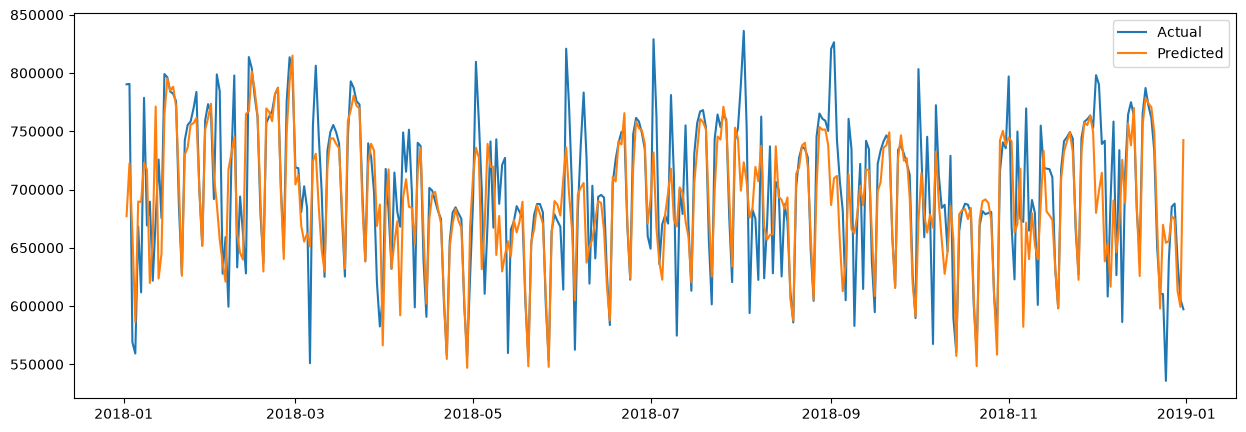

In [29]:
# Plot actual vs predicted values
plt.figure(figsize=(15, 5))
plt.plot(y_test, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.show()

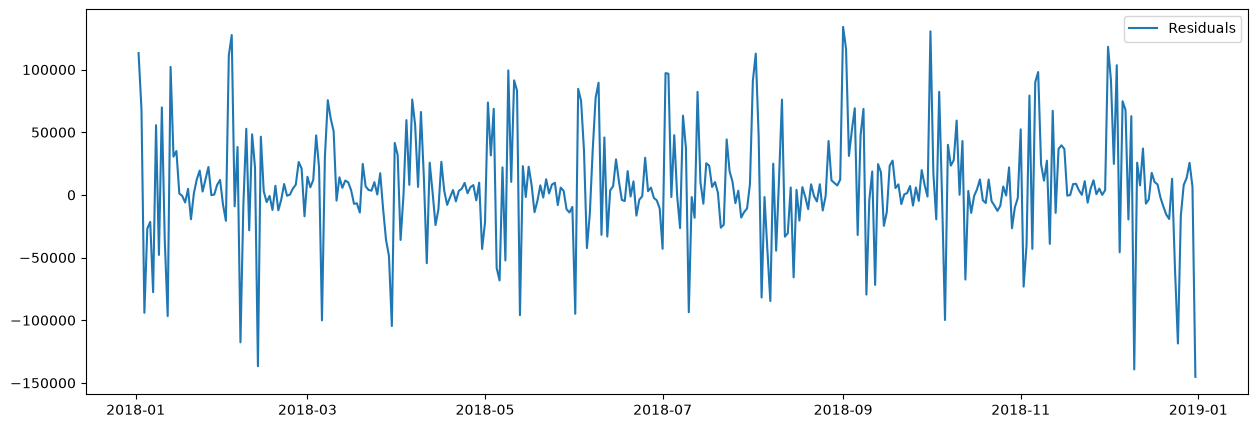

In [30]:
# Plot residuals
plt.figure(figsize=(15, 5))
plt.plot(residuals, label='Residuals')
plt.legend()
plt.show()

# Hyperparameter tuning

In [32]:
# Define the parameter grid
param_distributions = {
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "max_iter": [100, 200, 300, 400, 500],
    "max_leaf_nodes": [10, 20, 30, 40, 50],
    "min_samples_leaf": [1, 2, 3, 4, 5],
    "l2_regularization": [0.0, 0.1, 1.0, 10.0]
}

# Setup TimeSeriesSplit to prevent temporal data leakage
ts_cv = TimeSeriesSplit(n_splits=5)

# Initialize the randomized search
tuned_search = RandomizedSearchCV(
    estimator=HistGradientBoostingRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=20,                          # Number of parameter settings sampled
    scoring="neg_root_mean_squared_error", # Use negative RMSE (sklearn convention)
    cv=ts_cv,
    n_jobs=-1,                          # Use all CPU cores
    random_state=42
)

# Fit the search on training data
tuned_search.fit(X_train, y_train)

# Extract the best model and evaluate on the test set
best_hgb_model = tuned_search.best_estimator_

# Generate final predictions
y_pred_tuned = best_hgb_model.predict(X_test)

# Calculate final test metrics
final_rmse = root_mean_squared_error(y_test, y_pred_tuned)
final_mape = mean_absolute_percentage_error(y_test, y_pred_tuned)

print("--- Tuning Results ---")
print(f"Best Parameters: {tuned_search.best_params_}")
print(f"Tuned Test RMSE: {final_rmse:.4f}")
print(f"Tuned Test MAPE: {final_mape:.4f}")

--- Tuning Results ---
Best Parameters: {'min_samples_leaf': 5, 'max_leaf_nodes': 40, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 10.0}
Tuned Test RMSE: 43550.2213
Tuned Test MAPE: 0.0412


# Train and save optimized model

In [36]:
# Optimized model
optimized_model = HistGradientBoostingRegressor(**tuned_search.best_params_, random_state=42)

# Fit on the full training set
optimized_model.fit(X_train, y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",40
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",5
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",10.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [39]:
# Save the trained model file
model_dir = Path("..") / "models"
model_dir.mkdir(exist_ok=True) # Creates the models folder if it doesn't exist

# Define the complete target path
model_path = model_dir / "best_hist_gradient_boosting_model.pkl"

# Save the model artifact
joblib.dump(optimized_model, model_path)

['..\\models\\best_hist_gradient_boosting_model.pkl']

# Feature importance

In [47]:
# Calculate permutation importance
perm_importance_result = permutation_importance(
    optimized_model, 
    X_test, 
    y_test,
    scoring='neg_root_mean_squared_error', # RMSE is the scoring metric used for evaluation
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "RMSE_Increase_Mean": perm_importance_result.importances_mean,
    "RMSE_Increase_Std": perm_importance_result.importances_std
})

importance_df = importance_df.sort_values(by="RMSE_Increase_Mean", ascending=False).reset_index(drop=True)
importance_df.head(10)

,Feature,RMSE_Increase_Mean,RMSE_Increase_Std
0,day_of_week_num,19043.615350,781.910815
1,day,18008.120125,1386.892367
2,total load actual_lag_1d,16249.679050,1207.544360
3,total load actual_lag_2d,3308.129491,1058.034555
4,week_of_year,1217.061410,148.034272
5,total load actual_lag_7d,548.564820,392.874232
6,wind_deg,421.025716,158.404005
7,temp_min,305.015347,319.970196
8,temp_max,286.152492,192.611235
9,temp_lag_1d,229.995341,112.668824


<Axes: title={'center': 'Permutation Importance (RMSE Increase)'}, ylabel='Feature'>

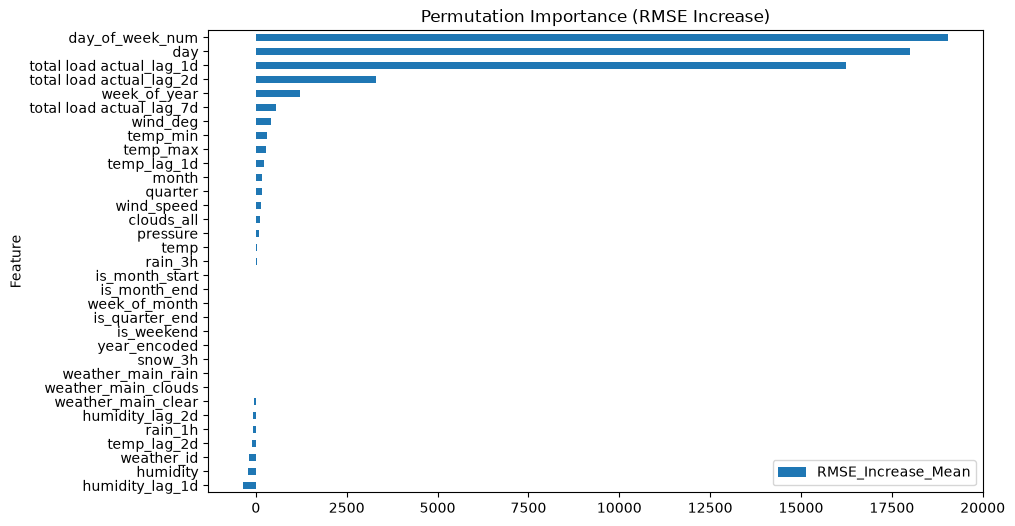

In [48]:
importance_df.sort_values(by="RMSE_Increase_Mean").plot(
    x="Feature",
    y="RMSE_Increase_Mean",
    kind="barh",
    figsize=(10, 6),
    title="Permutation Importance (RMSE Increase)"
)

In [56]:
# Feature to keep
importance_df[importance_df["RMSE_Increase_Mean"] > 0]["Feature"].tolist()

['day_of_week_num',
 'day',
 'total load actual_lag_1d',
 'total load actual_lag_2d',
 'week_of_year',
 'total load actual_lag_7d',
 'wind_deg',
 'temp_min',
 'temp_max',
 'temp_lag_1d',
 'month',
 'quarter',
 'wind_speed',
 'clouds_all',
 'pressure',
 'temp',
 'rain_3h',
 'is_month_start']

In [58]:
# Only keep useful features
useful_features = [
    'day_of_week_num',
    'day',
    'total load actual_lag_1d',
    'total load actual_lag_2d',
    'week_of_year',
    'total load actual_lag_7d',
    'wind_deg',
    'temp_min',
    'temp_max',
    'temp_lag_1d',
    'month',
    'quarter',
    'wind_speed',
    'clouds_all',
    'pressure',
    'temp',
    'rain_3h',
    'is_month_start'
]
df[useful_features + ['total load actual']].shape

(1455, 19)

# Re-train and re-save

In [59]:
# Optimized model
optimized_model = HistGradientBoostingRegressor(**tuned_search.best_params_, random_state=42)

# Fit on only the useful features in the training set
optimized_model.fit(X_train[useful_features], y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",40
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",5
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",10.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [60]:
# Save the trained model file
model_dir = Path("..") / "models"
model_dir.mkdir(exist_ok=True) # Creates the models folder if it doesn't exist

# Define the complete target path
model_path = model_dir / "best_hist_gradient_boosting_model.pkl"

# Save the model artifact
joblib.dump(optimized_model, model_path)

['..\\models\\best_hist_gradient_boosting_model.pkl']